<h3><center>Introduction to building a quant pricing library</center></h3>
<h1><center>Building Blocks of the Framework</center></h1>
<h3><center>Gabor Friedmann</center></h3>
<h4><center>7 October, 2026</center></h4>

## What did we learn last time?

<b>Risk-free interest rate</b> ($r$): Annual return of a riskless investment, i.e. the minimum return an investor expects for any investment.

<b>Spot contract</b>: An agreement between two parties (a buyer and a seller) to trade an asset "*immediately*".

Fair value: $ S_t $

The buyer of a contract takes a *Long* position, while the seller of a contract takes a *Short* position.

<b>Forward contract</b>: An agreement between two parties (a buyer and a seller) to trade an underlying asset at a <u>certain price</u> ($K$: strike) on a <u>certain future date</u> ($T$: expiry). This is an <u>obligation</u> to both parties.

Payoff at expiry (LF): $ \;\;\; S_T-K $

<img src="./img/payoff_forward.jpg" style="margin-left:auto; margin-right:auto; width: 730px;" />

<b>(European) Call option contract</b>: The option buyer has the <u>right</u>, but not the obligation, to <u><b>buy</b></u> an underlying asset at a certain price ($K$: strike) on a certain future date ($T$: expiry). If option is exercised by buyer, the option seller must <u>sell</u> the underlying asset.

Payoff at expiry (LC): $ \;\;\; max\lbrace S_T-K, 0\rbrace $

<img src="./img/payoff_call.jpg" style="margin-left:auto; margin-right:auto; width: 730px;" />

<b>(European) Put option contract</b>: The option buyer has the <u>right</u>, but not the obligation, to <u><b>sell</b></u> an underlying asset at a certain price ($K$: strike) on a certain future date ($T$: expiry). If option is exercised by the option buyer, the option seller must <u>buy</u> the underlying asset.

Payoff at expiry (LP): $ \;\;\; max\lbrace K-S_T, 0\rbrace $

<img src="./img/payoff_put.jpg" style="margin-left:auto; margin-right:auto; width: 730px;" />

## Pricing under Black-Scholes model assumptions
Spot price: $ S_t $, strike price: $ K $, expiry: $ T $, volatility of underlying: $ \sigma $, risk-free rate: $ r $

<b>Forward (LF)</b>: $ \;\;\; f_t = S_t - Ke^{-r(T-t)} $

<b>Call option (LC)</b>: $ \;\;\; c_t = S_tN(d_1) - Ke^{-r(T-t)}N(d_2) $

<b>Put option (LP)</b>: $ \;\;\; p_t = Ke^{-r(T-t)}N(-d_2) - S_tN(-d_1) $

where $N(\cdot)$ is the standard normal CDF

$ d_1 = \dfrac{1}{\sigma\sqrt{T-t}}\left[ln\left(\dfrac{S_t}{K}\right)+\left(r+\dfrac{\sigma^2}{2}\right)(T-t)\right] \;\;\;\;\;\;\;\;\;\; d_2 = d_1 - \sigma\sqrt{T-t} $

<br>
<b>Put-call parity</b>: $ LF=LC+SP $

$ f_t=c_t-p_t $

## Warm up exercise

Let's price a real life European call option contract on a Google stock using Black-Scholes model.

Data:

* https://finance.yahoo.com/quote/GOOG/options?p=GOOG
* https://www.marketwatch.com/investing/bond/tmubmusd01y

<img src="./img/pricing_example.jpg" style="margin-left:auto; margin-right:auto" />

In [1]:
import numpy as np
from scipy.stats import norm

def black_scholes_european_call(S0: float, K: float, T: float, sigma: float, r: float):
    d1 = ( np.log( S0 / K ) + ( r + 0.5 * sigma**2 ) * T ) / ( sigma * T**0.5 )
    d2 = d1 - sigma * T**0.5
    N_d1 = norm.cdf(d1)
    N_d2 = norm.cdf(d2)
    df = np.exp((-1.0)*r*T)
    return S0 * N_d1 - K * df * N_d2

C:\Users\ikt6300\AppData\Roaming\Python\Python310\site-packages\scipy\__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
import pandas as pd

df = pd.read_csv('GOOG.csv', usecols=['Date', 'Close'], index_col='Date')
df['CloseTM1'] = df['Close'].shift(1)
df['LogReturn'] = np.log(df['Close'] / df['CloseTM1'])

daily_log_return_std = np.std(df['LogReturn'], ddof=1)
# Annualization: ~260 weekdays per year
volatility = daily_log_return_std * np.sqrt(260)

print(f'Historical volatility: {round(volatility*100, 2)}%')

Historical volatility: 31.58%


In [3]:
import datetime as dt

today = dt.date(2026, 10, 7)

spot = ...
strike = ...
expiry = (dt.date(...) - today).days / 365
vol = ...
rate = ...

premium = black_scholes_european_call(spot, strike, expiry, vol, rate)
print(f'Premium: {round(premium, 2)}$')

TypeError: 'ellipsis' object cannot be interpreted as an integer

## How to build a pricing library?

<b>Goal</b>: Implement a coherent code base that is able to calculate fair value and greeks of various contracts in a generic way.

<b>Requirements</b>:
* Separate market data from pricing code
* Reusability: Avoid code duplication
* Scalability: Should be fairly easy to onboard a new contract or a pricer
* Encapsulation: Bundle related data and funcionalities into a structured unit

<img src="./img/building_blocks_empty.jpg" style="margin-left:auto; margin-right:auto; width: 1000px;" />

<img src="./img/building_blocks_full.jpg" style="margin-left:auto; margin-right:auto; width: 1000px;" />

<img src="./img/contracts.jpg" style="margin-left:auto; margin-right:auto; width: 800px;" />

## Important concepts

<b>Inheritance</b>: Deriving a class (Derived/Child/Sub) from another class (Base/Parent/Super) that share a set of properties and methods.

<b>Abstract Base Class (ABC)</b>: Such a class is not concrete and cannot be instantiated. Instead, it forces derived classes to implement all abstract properties and methods.


<b>Let's build the library!</b>

# Tasks

## MarketData - market_data.py

* Define the necessary market data (spot, volatility, risk-free rate) in MarketData class.


| Risk-free rate |
| :-: |
| 0.05 |


| Underlying | Spot | Volatility |
| :- | :-: | :-: |
| Stock.BLUECHIP_BANK | 130.17 | 0.381 |
| Stock.TIPTOP_SOLUTIONS | 177.32 | 0.320 |


## Market Model - model.py

* Define MarketModel class.
* Define its __init__() method:
    * Take an underlying Stock as input.
    * Store the underlying and the corresponding market data (risk-free rate, spot, volatility).
* Implement calc_df() method which takes a tenor and returns the corresponding discount factor.


## Contract - contract.py

* Implement payoff() methods in derived classes
* Make it compulsory to implement these methods for future enhancements

## Pricer - pricer.py

* Implement calc_fair_value() method in EuropeanAnalyticPricer.


## Test - test_pricer.py

* Create put-call parity test for fair value and all greeks using various underlying, strike, expiry.

# Assignments - Digital options

Create a new folder under <b>QuantCourseBP\homeworks</b> and copy over the content of this lecture's solution folder to start with.

1. Get familiar with digital options and implement EuropeanDigitalContract and EuropeanDigitalAnalyticPricer (fair value and greeks) in the library. Implement unit test for fair value using pytest. **(12 points)**
2. Get familiar with bull spread options and by utilizing EuropeanDigitalAnalyticPricer and EuropeanAnalyticPricer, create a figure to visualize that a digital call option can be thought of as a limit of bull spread call options. **(8 points)**

In [1]:
# Add current folder and QuantCourseBP folder to syspath to import modules
import sys
from pathlib import Path
current = Path(Path().resolve())
sys.path.append(str(current))
sys.path.append(str(current.parents[2]))

from enum import *
from pricer import *

C:\Users\ikt6300\AppData\Roaming\Python\Python310\site-packages\scipy\__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


QuantCourseBP e8bc6326c037d34c1bfdbc6fadcc926f84602017*


In [2]:
import pricer

print("Notebook working folder:", current)
print("Loaded pricer from:", pricer.__file__)
print(
    "Enums file found:",
    (current.parents[2] / "src" / "enums.py").exists()
)


Notebook working folder: C:\Users\ikt6300\OneDrive - Budapesti Műszaki és Gazdaságtudományi Egyetem\2026_27\2026_27_1\Pénzügyi folyamatok\QuantCourseBP\Lectures\2026_fall_BME\05_BuildingBlocks
Loaded pricer from: C:\Users\ikt6300\OneDrive - Budapesti Műszaki és Gazdaságtudományi Egyetem\2026_27\2026_27_1\Pénzügyi folyamatok\QuantCourseBP\Lectures\2026_fall_BME\05_BuildingBlocks\pricer.py
Enums file found: True


In [3]:
from pricer import  EuropeanDigitalAnalyticPricer

print("Ready to try the digital-option cells")


Ready to try the digital-option cells


In [4]:
stock = Stock.BLUECHIP_BANK
model = MarketModel(stock)
K = 130.0
T = 1.0

call = EuropeanDigitalContract(
    stock, PutCallFwd.CALL, LongShort.LONG, K, T
)
put = EuropeanDigitalContract(
    stock, PutCallFwd.PUT, LongShort.LONG, K, T
)

call_pricer = EuropeanDigitalAnalyticPricer(call, model, Params())
put_pricer = EuropeanDigitalAnalyticPricer(put, model, Params())

for terminal_spot in [100, 130, 160]:
    at_expiry = {call.get_timeline()[0]: terminal_spot}
    print(
        f"S(T)={terminal_spot}: "
        f"call payoff={call.payoff(at_expiry):.0f}, "
        f"put payoff={put.payoff(at_expiry):.0f}"
    )

call_price = call_pricer.calc_fair_value()
put_price = put_pricer.calc_fair_value()

print(f"\nCall price: {call_price:.6f}")
print(f"Put price:  {put_price:.6f}")
print(f"Sum:        {call_price + put_price:.6f}")
print(f"Discount:   {model.calc_df(T):.6f}")

for name in ["delta", "gamma", "vega", "theta", "rho"]:
    method = "calc_" + name
    print(
        f"{name:5s}: "
        f"call={getattr(call_pricer, method)(): .6f}, "
        f"put={getattr(put_pricer, method)(): .6f}"
    )


S(T)=100: call payoff=0, put payoff=1
S(T)=130: call payoff=0, put payoff=0
S(T)=160: call payoff=1, put payoff=0

Call price: 0.454437
Put price:  0.496793
Sum:        0.951229
Discount:   0.951229
delta: call= 0.007640, put=-0.007640
gamma: call=-0.000050, put= 0.000050
vega : call=-0.323367, put= 0.323367
theta: call= 0.034599, put= 0.012962
rho  : call= 0.540037, put=-1.491267


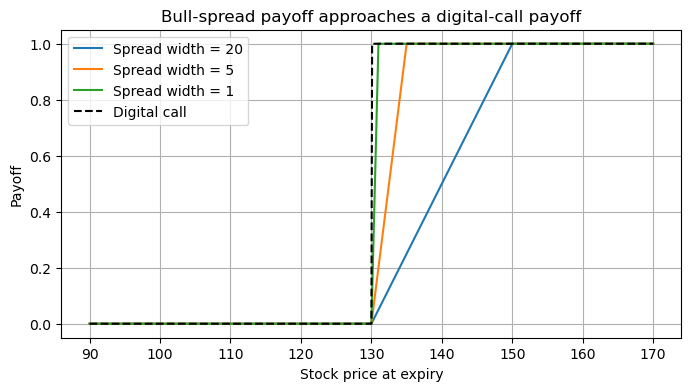

In [6]:
import matplotlib.pyplot as plt

terminal_spots = np.linspace(90, 170, 801)
digital_payoffs = (terminal_spots > K).astype(float)

plt.figure(figsize=(8, 4))

for width in [20, 5, 1]:
    lower_call = np.maximum(terminal_spots - K, 0)
    upper_call = np.maximum(terminal_spots - (K + width), 0)
    bull_spread = (lower_call - upper_call) / width

    plt.plot(
        terminal_spots, bull_spread,
        label=f"Spread width = {width}"
    )

plt.plot(
    terminal_spots, digital_payoffs,
    "k--", label="Digital call"
)

plt.xlabel("Stock price at expiry")
plt.ylabel("Payoff")
plt.title("Bull-spread payoff approaches a digital-call payoff")
plt.legend()
plt.grid(True)
plt.show()


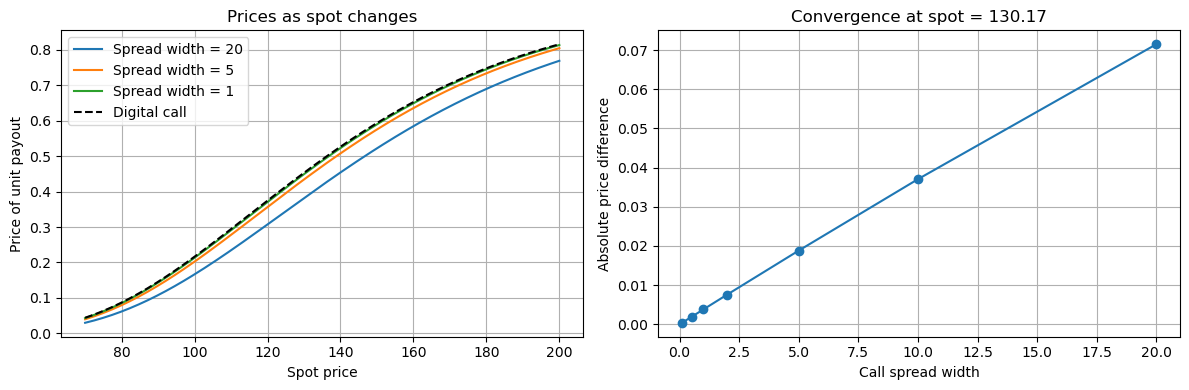

In [7]:
def digital_price(spot):
    m = MarketModel(stock)
    m.spot = float(spot)

    contract = EuropeanDigitalContract(
        stock, PutCallFwd.CALL, LongShort.LONG, K, T
    )
    return EuropeanDigitalAnalyticPricer(
        contract, m, Params()
    ).calc_fair_value()


def spread_price(spot, width):
    m = MarketModel(stock)
    m.spot = float(spot)

    long_call = EuropeanContract(
        stock, PutCallFwd.CALL, LongShort.LONG, K, T
    )
    short_call = EuropeanContract(
        stock, PutCallFwd.CALL, LongShort.SHORT, K + width, T
    )

    lower = EuropeanAnalyticPricer(
        long_call, m, Params()
    ).calc_fair_value()
    upper = EuropeanAnalyticPricer(
        short_call, m, Params()
    ).calc_fair_value()

    return (lower + upper) / width


spots = np.linspace(70, 200, 160)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: compare prices across different current stock prices.
for width in [20, 5, 1]:
    prices = [spread_price(s, width) for s in spots]
    axes[0].plot(spots, prices, label=f"Spread width = {width}")

axes[0].plot(
    spots,
    [digital_price(s) for s in spots],
    "k--",
    label="Digital call"
)
axes[0].set(
    title="Prices as spot changes",
    xlabel="Spot price",
    ylabel="Price of unit payout"
)
axes[0].legend()
axes[0].grid(True)

# Right: compare errors as the spread becomes narrower.
widths = [20, 10, 5, 2, 1, 0.5, 0.1]
errors = [
    abs(spread_price(model.spot, width) - digital_price(model.spot))
    for width in widths
]

axes[1].plot(widths, errors, "o-")
axes[1].set(
    title=f"Convergence at spot = {model.spot}",
    xlabel="Call spread width",
    ylabel="Absolute price difference"
)
axes[1].grid(True)

plt.tight_layout()
plt.show()
